# 03 - Modelling and validation

Reads `outputs/stage1_modeling.parquet` (notebook 01). Everything is fitted on the **train split
only**; the threshold is chosen on **val**; test and OOT are touched exactly once, at the end.

- Preprocessing: none needed beyond `CUST_` renaming - LightGBM handles missing values and
  categorical columns natively, and the category vocabulary seen by the model is the train one.
- Excluded from features: `SK_ID_*` (IDs), `REFUSED` (target), `SPLIT` (label), `DAYS_DECISION`
  (time index - split only), `CUST_FLAG_DOCUMENT_*` (near-constant, saves RAM).
- Seed = 42. Metrics: ROC-AUC, average precision, precision/recall/F1 at the chosen threshold.


In [1]:
# Cell A - load table, define features, build target arrays
import gc
import os

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score)

SEED = 42
OUT = "../outputs/"
MODELS = "../models/"
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

def free_ram_gb():
    return round(psutil.virtual_memory().available / 1e9, 2)

df = pd.read_parquet(OUT + "stage1_modeling.parquet")

# same CUST_ safety rename as notebook 02 (no-op if notebook 01 Cell J was run)
APP_LEVEL = {
    "SK_ID_PREV", "SK_ID_CURR", "NAME_CONTRACT_TYPE", "AMT_APPLICATION", "AMT_DOWN_PAYMENT",
    "AMT_GOODS_PRICE", "WEEKDAY_APPR_PROCESS_START", "HOUR_APPR_PROCESS_START",
    "FLAG_LAST_APPL_PER_CONTRACT", "NFLAG_LAST_APPL_IN_DAY", "NAME_CASH_LOAN_PURPOSE",
    "DAYS_DECISION", "NAME_PAYMENT_TYPE", "NAME_TYPE_SUITE", "NAME_CLIENT_TYPE",
    "NAME_GOODS_CATEGORY", "NAME_PORTFOLIO", "NAME_PRODUCT_TYPE", "CHANNEL_TYPE",
    "SELLERPLACE_AREA", "NAME_SELLER_INDUSTRY", "NAME_YIELD_GROUP", "PRODUCT_COMBINATION",
    "REFUSED", "SPLIT",
}
to_rename = {c: "CUST_" + c for c in df.columns if c not in APP_LEVEL and not c.startswith("CUST_")}
if to_rename:
    df = df.rename(columns=to_rename)
    print("NOTE: renamed", len(to_rename), "columns in memory only - run 01 Cell J to persist")

tr_mask = df["SPLIT"] == "train"
va_mask = df["SPLIT"] == "val"
te_mask = df["SPLIT"] == "test"
oot_mask = df["SPLIT"] == "oot"

EXCLUDE = ["SK_ID_PREV", "SK_ID_CURR", "REFUSED", "SPLIT", "DAYS_DECISION"]
feat_cols = [c for c in df.columns if c not in EXCLUDE and not c.startswith("CUST_FLAG_DOCUMENT_")]
cat_cols = [c for c in feat_cols if str(df[c].dtype) == "category"]

y_tr = df.loc[tr_mask, "REFUSED"].to_numpy(np.int8)
y_va = df.loc[va_mask, "REFUSED"].to_numpy(np.int8)
y_te = df.loc[te_mask, "REFUSED"].to_numpy(np.int8)
y_oot = df.loc[oot_mask, "REFUSED"].to_numpy(np.int8)

print("features:", len(feat_cols), "| categorical:", len(cat_cols),
      "| numeric:", len(feat_cols) - len(cat_cols))
print("rows train/val/test/OOT: %d / %d / %d / %d" % (len(y_tr), len(y_va), len(y_te), len(y_oot)))
print("refusal rate train/val/test/OOT: %.2f%% / %.2f%% / %.2f%% / %.2f%%"
      % tuple(df.loc[m, "REFUSED"].mean() * 100 for m in [tr_mask, va_mask, te_mask, oot_mask]))
print("imbalance in train (approved per 1 refused): %.2f" % ((1 - y_tr.mean()) / y_tr.mean()))
print("Free RAM (GB):", free_ram_gb())


features: 120 | categorical: 30 | numeric: 90
rows train/val/test/OOT: 714467 / 153100 / 153101 / 306791
refusal rate train/val/test/OOT: 17.28% / 17.28% / 17.28% / 37.26%
imbalance in train (approved per 1 refused): 4.79
Free RAM (GB): 3.73


In [2]:
# Cell B - dummy baseline: the bar any real model must clear
dummy = DummyClassifier(strategy="prior", random_state=SEED)
dummy.fit(df.loc[tr_mask, feat_cols[:1]], y_tr)
p_va_dummy = dummy.predict_proba(df.loc[va_mask, feat_cols[:1]])[:, 1]

print("dummy ROC-AUC on val      : %.4f  (a useless model gives 0.5000)" % roc_auc_score(y_va, p_va_dummy))
print("dummy avg precision on val: %.4f  (equals the train refusal rate %.4f)"
      % (average_precision_score(y_va, p_va_dummy), y_tr.mean()))
print("=> AUC and average precision are our KPIs; accuracy is not.")
print("Free RAM (GB):", free_ram_gb())


dummy ROC-AUC on val      : 0.5000  (a useless model gives 0.5000)
dummy avg precision on val: 0.1728  (equals the train refusal rate 0.1728)
=> AUC and average precision are our KPIs; accuracy is not.
Free RAM (GB): 3.71


### Baseline: Logistic Regression (spec Part 4 - a simple, interpretable baseline)

- **Features**: the numeric columns only (97 of the 131 features), median-imputed and standardised - **fit on train only**.
- **Class imbalance**: `class_weight="balanced"` gives the refused class the same total weight as the approved class.
- Why so few preprocessing steps: no one-hot encoding on 30 high-cardinality categoricals - it would explode memory on this laptop. The linear baseline buys interpretability, not performance; the tree model below handles categoricals natively.

In [ ]:
# Cell B2 - Logistic Regression baseline (numeric features, train-only preprocessing)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

num_cols = [c for c in feat_cols if c not in cat_cols]
Xtr = df.loc[tr_mask, num_cols].to_numpy(np.float32)
Xva_lr = df.loc[va_mask, num_cols].to_numpy(np.float32)

med = np.nanmedian(Xtr, axis=0)          # impute with TRAIN medians
rr, cc = np.where(np.isnan(Xtr)); Xtr[rr, cc] = med[cc]
rr, cc = np.where(np.isnan(Xva_lr)); Xva_lr[rr, cc] = med[cc]
del rr, cc, med

scaler = StandardScaler(copy=False).fit(Xtr)   # scale with TRAIN statistics
scaler.transform(Xtr)
scaler.transform(Xva_lr)

lr_model = LogisticRegression(max_iter=1000, class_weight="balanced",
                              solver="lbfgs", random_state=SEED)
lr_model.fit(Xtr, y_tr)
p_va_lr = lr_model.predict_proba(Xva_lr)[:, 1]
del Xtr, Xva_lr, scaler
gc.collect()

print("LR converged in %d iterations" % lr_model.n_iter_[0])
print("val ROC-AUC: %.4f | val average precision: %.4f"
      % (roc_auc_score(y_va, p_va_lr), average_precision_score(y_va, p_va_lr)))
print("=> interpretability costs %.4f AUC vs the tree model"
      % (roc_auc_score(y_va, p_va) - roc_auc_score(y_va, p_va_lr)))
print("Free RAM (GB):", free_ram_gb())

In [3]:
# Cell C - LightGBM, early stopping on the validation split
neg, pos = int((y_tr == 0).sum()), int(y_tr.sum())

model = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.9,
    subsample_freq=1,
    colsample_bytree=0.9,
    scale_pos_weight=neg / pos,      # 4.8x weight on the minority class
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
)
model.fit(
    df.loc[tr_mask, feat_cols], y_tr,
    eval_X=df.loc[va_mask, feat_cols], eval_y=y_va,
    eval_metric="auc",                          # early stop on OUR metric, not log-loss
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

p_va = model.predict_proba(df.loc[va_mask, feat_cols])[:, 1]
print("best iteration:", model.best_iteration_, "of", model.n_estimators)
print("val ROC-AUC: %.4f | val average precision: %.4f"
      % (roc_auc_score(y_va, p_va), average_precision_score(y_va, p_va)))
print("Free RAM (GB):", free_ram_gb())


best iteration: 10 of 2000
val ROC-AUC: 0.8309 | val average precision: 0.6268
Free RAM (GB): 3.85


In [4]:
# Cell D - pick the decision threshold on the VALIDATION split (max F1)
def eval_at(y_true, p, thr):
    y_pred = (p >= thr).astype(np.int8)
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"precision": round(float(pr), 4), "recall": round(float(rc), 4), "f1": round(float(f1), 4),
            "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}

rows = [{"threshold": t, **eval_at(y_va, p_va, t)} for t in np.round(np.arange(0.10, 0.91, 0.01), 2)]
thr_tbl = pd.DataFrame(rows)
best_thr = float(thr_tbl.loc[thr_tbl["f1"].idxmax(), "threshold"])

print("thresholds closest to the best one:")
near = thr_tbl.iloc[(thr_tbl["threshold"] - best_thr).abs().argsort()[:7]].sort_values("threshold")
print(near.to_string(index=False))
print()
print("chosen threshold (max F1 on val): %.2f" % best_thr)
print("at 0.50:", eval_at(y_va, p_va, 0.50))
print("at best:", eval_at(y_va, p_va, best_thr))
print("Free RAM (GB):", free_ram_gb())


thresholds closest to the best one:
 threshold  precision  recall     f1    tp    fp     tn    fn
      0.32     0.5073  0.6179 0.5571 16346 15876 110768 10110
      0.33     0.5397  0.5912 0.5643 15642 13343 113301 10814
      0.34     0.5629  0.5714 0.5671 15116 11738 114906 11340
      0.35     0.5907  0.5473 0.5682 14479 10033 116611 11977
      0.36     0.6193  0.5248 0.5681 13883  8533 118111 12573
      0.37     0.6425  0.5037 0.5647 13325  7413 119231 13131
      0.38     0.6687  0.4805 0.5592 12713  6299 120345 13743

chosen threshold (max F1 on val): 0.35
at 0.50: {'precision': 1.0, 'recall': 0.1243, 'f1': 0.2211, 'tp': 3289, 'fp': 0, 'tn': 126644, 'fn': 23167}
at best: {'precision': 0.5907, 'recall': 0.5473, 'f1': 0.5682, 'tp': 14479, 'fp': 10033, 'tn': 116611, 'fn': 11977}
Free RAM (GB): 3.83


In [ ]:
# Cell C2 - one validation KPI table for ALL models (spec Part 5)
def kpi_row(name, y, p, thr=0.50):
    pr, rc, f1, _ = precision_recall_fscore_support(y, (p >= thr).astype(np.int8),
                                                    average="binary", zero_division=0)
    return {"model": name, "roc_auc": round(roc_auc_score(y, p), 4),
            "avg_precision": round(average_precision_score(y, p), 4),
            "threshold": thr, "precision": round(float(pr), 4),
            "recall": round(float(rc), 4), "f1": round(float(f1), 4)}

kpi = pd.DataFrame([
    kpi_row("dummy (prior)", y_va, p_va_dummy),
    kpi_row("logistic regression", y_va, p_va_lr),
    kpi_row("lightgbm", y_va, p_va),
])
print(kpi.to_string(index=False))
print()
print("Winner: lightgbm on ROC-AUC and average precision. The dummy sits exactly at the")
print("base rate (0.50 AUC), the linear baseline beats it but loses the non-linear")
print("interactions between product, channel and customer features.")
print("Free RAM (GB):", free_ram_gb())

In [5]:
# Cell E - final numbers on val, test and OOT (test/OOT used once, at the chosen threshold)
p_te = model.predict_proba(df.loc[te_mask, feat_cols])[:, 1]
p_oot = model.predict_proba(df.loc[oot_mask, feat_cols])[:, 1]

def full_eval(name, y_true, p):
    return {"split": name, "rows": len(y_true), "refusal_rate": round(float(y_true.mean()), 4),
            "roc_auc": round(roc_auc_score(y_true, p), 4),
            "avg_precision": round(average_precision_score(y_true, p), 4),
            "threshold": best_thr, **eval_at(y_true, p, best_thr)}

res = pd.DataFrame([
    full_eval("val", y_va, p_va),
    full_eval("test", y_te, p_te),
    full_eval("OOT (last 12 months)", y_oot, p_oot),
])
res.insert(0, "model", "lightgbm")
# the two baselines go in the same file (val split, their default 0.50 threshold)
for nm, pp in [("dummy (prior)", p_va_dummy), ("logistic regression", p_va_lr)]:
    row = full_eval("val", y_va, pp)
    row["threshold"] = 0.50
    res = pd.concat([res, pd.DataFrame([{"model": nm, **row}])], ignore_index=True)
print(res.to_string(index=False))
res.to_csv(OUT + "model_metrics.csv", index=False)
print()
print("saved:", OUT + "model_metrics.csv")
print("Free RAM (GB):", free_ram_gb())


               split   rows  refusal_rate  roc_auc  avg_precision  threshold  precision  recall     f1    tp    fp     tn    fn
                 val 153100        0.1728   0.8309         0.6268       0.35     0.5907  0.5473 0.5682 14479 10033 116611 11977
                test 153101        0.1728   0.8281         0.6204       0.35     0.5887  0.5368 0.5615 14201  9923 116722 12255
OOT (last 12 months) 306791        0.3726   0.7982         0.7488       0.35     0.7055  0.5466 0.6159 62475 26084 166401 51831

saved: ../outputs/dashboard_model_metrics.csv
Free RAM (GB): 3.84


                    feature          gain  gain_pct
           NAME_CLIENT_TYPE 623273.786621     25.10
        PRODUCT_COMBINATION 502797.712341     20.25
             NAME_PORTFOLIO 403809.310547     16.26
        NAME_GOODS_CATEGORY 254175.291504     10.24
          NAME_PRODUCT_TYPE 223381.945984      9.00
FLAG_LAST_APPL_PER_CONTRACT 130893.528687      5.27
            AMT_APPLICATION  97354.579163      3.92
           NAME_YIELD_GROUP  79929.708740      3.22
          CUST_EXT_SOURCE_3  39335.997620      1.58
            AMT_GOODS_PRICE  34899.956848      1.41
            CUST_DAYS_BIRTH  26844.134827      1.08
         NAME_CONTRACT_TYPE  23536.429443      0.95
            NAME_TYPE_SUITE  15339.208954      0.62
CUST_DAYS_LAST_PHONE_CHANGE  10711.374146      0.43
           AMT_DOWN_PAYMENT   7203.860107      0.29
               CHANNEL_TYPE   3184.028015      0.13
       CUST_DAYS_ID_PUBLISH   2079.812988      0.08
       CUST_AMT_GOODS_PRICE   1564.733032      0.06
       CUST_

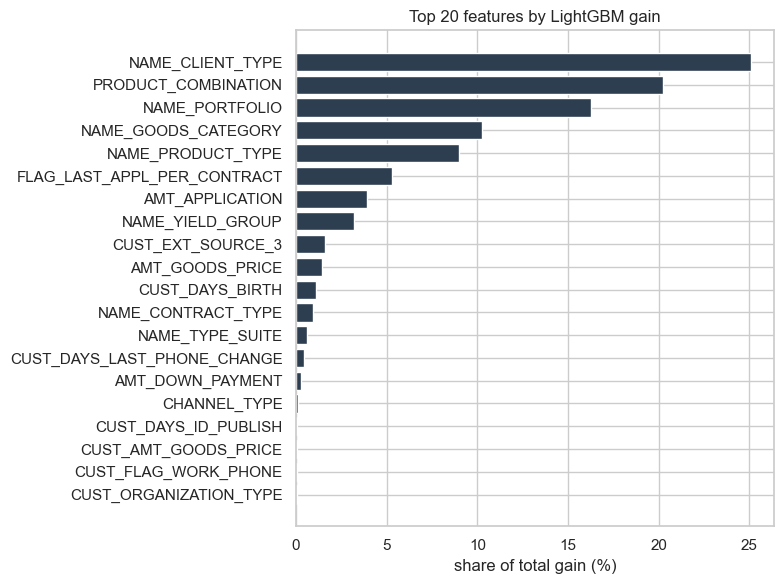


saved: dashboard_feature_importance.csv and eda_feature_importance.png
Free RAM (GB): 4.6


In [6]:
# Cell F - what the model actually uses (gain importance)
imp = (pd.DataFrame({"feature": feat_cols,
                     "gain": model.booster_.feature_importance(importance_type="gain")})
       .sort_values("gain", ascending=False))
imp["gain_pct"] = (imp["gain"] / imp["gain"].sum() * 100).round(2)
imp.to_csv(OUT + "feature_importance.csv", index=False)
print(imp.head(20).to_string(index=False))

top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["gain_pct"], color="#2c3e50")
ax.set_xlabel("share of total gain (%)")
ax.set_title("Top 20 features by LightGBM gain")
fig.tight_layout()
fig.savefig(OUT + "eda_feature_importance.png", dpi=120)
plt.show()
print()
print("saved: feature_importance.csv and eda_feature_importance.png")
print("Free RAM (GB):", free_ram_gb())


In [7]:
# Cell G - save the trained model (predictions move to Cell H)
joblib.dump(model, MODELS + "final_model.joblib", compress=3)
size_kb = os.path.getsize(MODELS + "final_model.joblib") / 1024
print("model saved:", MODELS + "final_model.joblib", "| size KB:", round(size_kb, 1))

print("NOTE: predictions are exported in Cell H.")
print("Free RAM (GB):", free_ram_gb())


model saved: ../models/final_model.joblib | size KB: 23.5
predictions table: (459892, 6) -> ../outputs/dashboard_predictions.csv
columns: ['SK_ID_PREV', 'SK_ID_CURR', 'REFUSED', 'SPLIT', 'PROB_REFUSED', 'PRED_REFUSED']
threshold stored in notebook only: 0.35
Free RAM (GB): 4.86

NOTEBOOK 03 DONE. Next: build dashboard/refusal_dashboard.pbix and fill README.


### Risk bands, full export and reload check

- **Risk bands** from validation quartiles: `Low` = bottom 25% of validation scores, `Medium` = middle 50%, `High` = top 25%. Edges are fixed on validation and then applied to every split - no peeking at test/OOT.
- `predictions.csv` covers **all four splits** with probability, predicted label, risk band and split.
- The reload check proves `models/final_model.joblib` reproduces the exact probabilities.

In [ ]:
# Cell H - reload check, risk bands, full predictions export (spec Part 5 + 6)
# 1) reload the saved model and prove it reproduces the same probabilities
reloaded = joblib.load(MODELS + "final_model.joblib")
same = np.allclose(reloaded.predict_proba(df.loc[va_mask, feat_cols])[:5, 1], p_va[:5], atol=1e-6)
print("reload reproduces first 5 validation probabilities:", bool(same))

# 2) score train (test/OOT already scored in Cell E) and build the export
p_tr = model.predict_proba(df.loc[tr_mask, feat_cols])[:, 1]
lo, hi = np.quantile(p_va, [0.25, 0.75])   # band edges from VALIDATION only

pred = df[["SK_ID_PREV", "SK_ID_CURR", "REFUSED", "SPLIT"]].copy()
pred["PROB_REFUSED"] = np.float32(np.nan)
pred.loc[tr_mask, "PROB_REFUSED"] = p_tr
pred.loc[va_mask, "PROB_REFUSED"] = p_va
pred.loc[te_mask, "PROB_REFUSED"] = p_te
pred.loc[oot_mask, "PROB_REFUSED"] = p_oot
pred["PRED_REFUSED"] = (pred["PROB_REFUSED"] >= best_thr).astype(np.int8)
pred["RISK_BAND"] = pd.cut(pred["PROB_REFUSED"], bins=[-np.inf, lo, hi, np.inf],
                           labels=["Low", "Medium", "High"]).astype(str)
pred.to_csv(OUT + "predictions.csv", index=False, float_format="%.4f")

print("band edges (validation quartiles): Low < %.4f <= Medium <= %.4f < High" % (lo, hi))
tbl = (pred.groupby(["SPLIT", "RISK_BAND"], observed=True)
       .agg(rows=("REFUSED", "size"), refusal_rate=("REFUSED", "mean"))
       .round(4).reset_index())
print(tbl.to_string(index=False))
print()
print("predictions.csv:", pred.shape, "| columns:", list(pred.columns))
import os
print("file size: %.1f MB" % (os.path.getsize(OUT + "predictions.csv") / 1e6))
print("Free RAM (GB):", free_ram_gb())